# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [1]:
# YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.1.1 - Configure the PEFT framework (QLoRA)
# ------------------------------------------------------------------
# Plan:
#   1. Prepare the training environment (seed, GPU check)
#   2. Load the base Qwen model in 4-bit (same nf4 settings as Notebooks 3-5)
#   3. Attach LoRA adapters to the q_proj and v_proj attention layers
#   4. Print how many parameters will actually be trained
# Loading the 4-bit base model + training the small LoRA adapters = QLoRA.

import torch
import random
import numpy as np
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

# ---- 1. Training environment ----
# Fix the random seeds so the training run can be reproduced
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Make sure the GPU is available
print("GPU available:", torch.cuda.is_available())
print("GPU name     :", torch.cuda.get_device_name(0))

# ---- 2. Load the base model in 4-bit ----
# Same model and the same quantisation settings as the earlier notebooks
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,                      # store the base weights in 4 bits
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16    # do the maths in float16
)

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=quant_config,
    device_map="auto"
)

# Get the 4-bit model ready for training (this also freezes the base weights
# and turns on gradient checkpointing, which saves GPU memory)
base_model = prepare_model_for_kbit_training(base_model)

# ---- 3. LoRA settings ----
lora_config = LoraConfig(
    r=16,                                    # rank of the small LoRA matrices
    lora_alpha=32,                           # scaling factor (rule of thumb: 2 x r)
    target_modules=["q_proj", "v_proj"],     # attention layers that get adapters
    lora_dropout=0.05,                       # small dropout to reduce overfitting
    bias="none",                             # do not train bias terms
    task_type="CAUSAL_LM"                    # we are training a text-generation model
)

# Attach the LoRA adapters to the frozen base model
peft_model = get_peft_model(base_model, lora_config)

# ---- 4. Confirm only a tiny part of the model will be trained ----
peft_model.print_trainable_parameters()

# Save the settings so we can record them for reproducibility later
print("\nLoRA settings: r =", lora_config.r,
      "| alpha =", lora_config.lora_alpha,
      "| targets =", lora_config.target_modules)

W1120 16:44:43.187000 34076 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1120 16:44:43.794000 34076 .venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


GPU available: True
GPU name     : NVIDIA GeForce RTX 4070 Laptop GPU


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410

LoRA settings: r = 16 | alpha = 32 | targets = {'v_proj', 'q_proj'}


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [2]:
# ------------------------------------------------------------------
# Task 4.1.2 - Configure the training parameters
# ------------------------------------------------------------------
# This cell:
#   1. Loads the tokenized train and validation data saved in Notebook 2
#   2. Sets the training hyperparameters (learning rate, batch size, steps)
#   3. Creates the AdamW optimizer for the LoRA adapter weights
#   4. Builds the DataLoaders that feed batches to the model
# It does not train anything yet. Training happens in Task 4.2.1.
# It needs peft_model and SEED from the 4.1.1 cell, so run that cell first.

import torch
from torch.optim import AdamW
from torch.utils.data import DataLoader
from datasets import load_from_disk

# ---- 1. Load the tokenized data from disk ----
train_data = load_from_disk("./tokenized_train")
valid_data = load_from_disk("./tokenized_valid")

# Keep only the columns the model needs, as PyTorch tensors.
# set_format must be applied again every time data is loaded from disk.
#   input_ids      -> text converted to token numbers
#   attention_mask -> 1 for real tokens, 0 for padding
#   labels         -> targets (padding is -100, so the loss ignores it)
columns_needed = ["input_ids", "attention_mask", "labels"]
train_data.set_format("torch", columns=columns_needed)
valid_data.set_format("torch", columns=columns_needed)

print("Train rows     :", len(train_data))
print("Validation rows:", len(valid_data))

# ---- 2. Training hyperparameters ----
LEARNING_RATE    = 2e-4   # standard LoRA learning rate
TRAIN_BATCH_SIZE = 4      # examples per training step (fits an 8 GB GPU)
VAL_BATCH_SIZE   = 8      # validation uses no gradients, so a bigger batch is fine
MAX_STEPS        = 300    # total training steps (about 0.4 of one epoch)
VAL_EVERY        = 25     # check validation loss every 25 steps
PATIENCE         = 3      # early stopping: stop after 3 checks with no improvement

# ---- 3. Optimizer ----
# AdamW updates only the parameters that are trainable (the LoRA adapter weights).
# The 4-bit base model stays frozen.
trainable_params = filter(lambda p: p.requires_grad, peft_model.parameters())
optimizer = AdamW(trainable_params, lr=LEARNING_RATE)

# ---- 4. DataLoaders ----
# A fixed random generator makes the shuffling the same on every run.
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_data,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,          # shuffle training data so batches are mixed
    generator=generator
)

valid_loader = DataLoader(
    valid_data,
    batch_size=VAL_BATCH_SIZE,
    shuffle=False          # no need to shuffle validation data
)

# ---- Check the configuration ----
print("\nTraining configuration")
print("Optimizer         : AdamW, learning rate =", LEARNING_RATE)
print("Quantisation      : 4-bit nf4, compute dtype float16 (QLoRA)")
print("Train batch size  :", TRAIN_BATCH_SIZE)
print("Max steps         :", MAX_STEPS)
print("Validate every    :", VAL_EVERY, "steps | patience =", PATIENCE)
print("Batches per epoch :", len(train_loader))
print("Epochs covered    :", round(MAX_STEPS / len(train_loader), 2))

# Look at one batch to confirm the shapes
batch = next(iter(train_loader))
print("\nOne batch input_ids shape:", batch["input_ids"].shape)
print("One batch labels shape   :", batch["labels"].shape)

Train rows     : 3121
Validation rows: 390

Training configuration
Optimizer         : AdamW, learning rate = 0.0002
Quantisation      : 4-bit nf4, compute dtype float16 (QLoRA)
Train batch size  : 4
Max steps         : 300
Validate every    : 25 steps | patience = 3
Batches per epoch : 781
Epochs covered    : 0.38

One batch input_ids shape: torch.Size([4, 128])
One batch labels shape   : torch.Size([4, 128])


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [3]:
# YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.2.1 - Execute fine-tuning (custom PyTorch training loop)
# ------------------------------------------------------------------
# What this cell does:
#   - Trains the LoRA adapters for up to MAX_STEPS steps
#   - Every VAL_EVERY steps, measures the validation loss
#   - Saves the adapter whenever the validation loss reaches a new best
#   - Stops early if validation loss does not improve for PATIENCE checks
# It needs peft_model, optimizer, train_loader, valid_loader and the
# settings (MAX_STEPS, VAL_EVERY, PATIENCE) from cells 4.1.1 and 4.1.2.
# Do NOT restart the kernel while it runs: the logs live in memory.

import time
import torch

# ---- Setup ----
device = next(peft_model.parameters()).device    # the GPU the model is on
peft_model.config.use_cache = False              # needed with gradient checkpointing
peft_model.train()                               # switch the model to training mode

# list of the trainable parameters (used for gradient clipping)
params_to_clip = [p for p in peft_model.parameters() if p.requires_grad]

# GradScaler prevents tiny float16 gradients from becoming zero
scaler = torch.amp.GradScaler("cuda")

MIN_DELTA = 0.001                      # smallest drop that counts as an improvement
BEST_DIR = "./intent_lora_best"        # where the best adapter is saved

# ---- Validation function ----
def evaluate():
    """Return the average loss over the whole validation set (no learning)."""
    peft_model.eval()
    total_loss = 0.0
    num_batches = 0
    with torch.no_grad():                                   # no gradients needed
        for val_batch in valid_loader:
            val_batch = {k: v.to(device) for k, v in val_batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                out = peft_model(**val_batch)
            total_loss += out.loss.item()
            num_batches += 1
    peft_model.train()                                      # back to training mode
    return total_loss / num_batches

# ---- Tracking variables ----
training_log = []            # one row per validation check: step, train_loss, val_loss
step_losses = []             # train loss of every single step (for the plot)
running_loss = 0.0           # train loss collected since the last validation check
running_count = 0
best_val_loss = float("inf")
best_step = 0
bad_checks = 0               # validation checks in a row with no improvement
stopped_early = False
start_time = time.time()

print("Training started...")

# ---- Training loop ----
for step, batch in enumerate(train_loader, start=1):

    # 1. Move the batch to the GPU
    batch = {k: v.to(device) for k, v in batch.items()}

    # 2. Forward pass: the model computes the loss from the labels
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        outputs = peft_model(**batch)
        loss = outputs.loss

    # 3. Backward pass: work out how to change the LoRA weights
    scaler.scale(loss).backward()

    # 4. Clip very large gradients, then update the weights with AdamW
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(params_to_clip, 1.0)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad()

    # 5. Remember the training loss
    step_losses.append(loss.item())
    running_loss += loss.item()
    running_count += 1

    # 6. Every VAL_EVERY steps: check validation loss
    if step % VAL_EVERY == 0:
        train_loss = running_loss / running_count
        val_loss = evaluate()
        running_loss, running_count = 0.0, 0

        training_log.append({"step": step, "train_loss": train_loss, "val_loss": val_loss})

        # Is this the best validation loss so far?
        if val_loss < best_val_loss - MIN_DELTA:
            best_val_loss = val_loss
            best_step = step
            bad_checks = 0
            peft_model.save_pretrained(BEST_DIR)     # save the best adapter
            note = "<- new best, adapter saved"
        else:
            bad_checks += 1
            note = f"(no improvement {bad_checks}/{PATIENCE})"

        minutes = (time.time() - start_time) / 60
        print(f"Step {step:4d} | train {train_loss:.4f} | val {val_loss:.4f} | "
              f"{minutes:.1f} min {note}")

        # Early stopping
        if bad_checks >= PATIENCE:
            print("\nEarly stopping: validation loss stopped improving.")
            stopped_early = True
            break

    # 7. Stop when the step limit is reached
    if step >= MAX_STEPS:
        break

# ---- Summary ----
total_minutes = (time.time() - start_time) / 60
print("\nTraining finished.")
print("Steps run          :", step)
print("Stopped early      :", stopped_early)
print("Best validation loss:", round(best_val_loss, 4), "at step", best_step)
print("Total time (min)   :", round(total_minutes, 1))

Training started...


C:\Users\divya\PycharmProjects\CapStoneRAGProject\.venv\lib\site-packages\torch\_dynamo\eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step   25 | train 2.5872 | val 1.3286 | 0.3 min <- new best, adapter saved
Step   50 | train 1.1148 | val 1.0210 | 0.6 min <- new best, adapter saved
Step   75 | train 0.9040 | val 0.8175 | 1.2 min <- new best, adapter saved
Step  100 | train 0.7306 | val 0.6813 | 1.7 min <- new best, adapter saved
Step  125 | train 0.6570 | val 0.6209 | 2.0 min <- new best, adapter saved
Step  150 | train 0.6088 | val 0.5856 | 2.5 min <- new best, adapter saved
Step  175 | train 0.5749 | val 0.5683 | 2.9 min <- new best, adapter saved
Step  200 | train 0.5750 | val 0.5510 | 3.4 min <- new best, adapter saved
Step  225 | train 0.5266 | val 0.5337 | 3.9 min <- new best, adapter saved
Step  250 | train 0.5347 | val 0.5237 | 4.4 min <- new best, adapter saved
Step  275 | train 0.5211 | val 0.5105 | 4.9 min <- new best, adapter saved
Step  300 | train 0.4823 | val 0.5030 | 5.4 min <- new best, adapter saved

Training finished.
Steps run          : 300
Stopped early      : False
Best validation loss: 0.503 

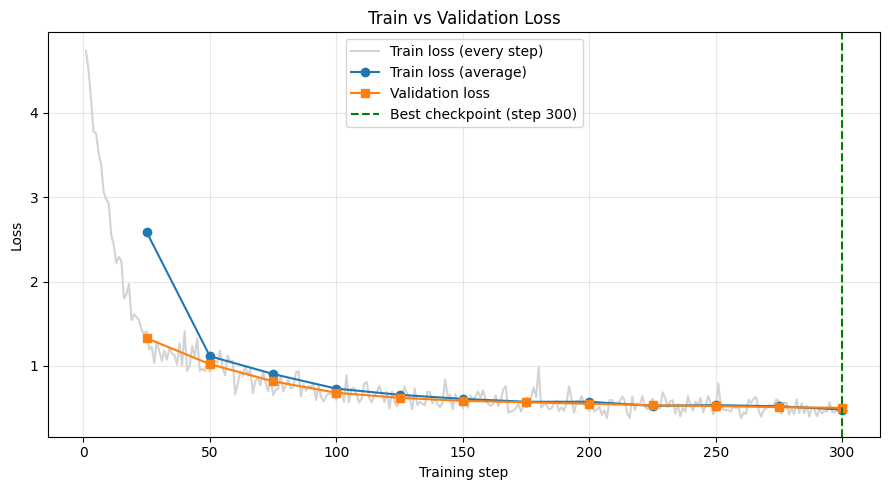

First check -> train: 2.5872 | val: 1.3286
Last check  -> train: 0.4823 | val: 0.503
Gap (val - train) at the last check: 0.0208
Saved training_curves.png


In [4]:
# YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.2.1 - Plot the train vs validation loss curves
# ------------------------------------------------------------------
# Saves the plot as training_curves.png (required evidence for the report).

import pandas as pd
import matplotlib.pyplot as plt

log_df = pd.DataFrame(training_log)

plt.figure(figsize=(9, 5))

# thin line: the loss of every single training step
plt.plot(range(1, len(step_losses) + 1), step_losses,
         color="lightgray", label="Train loss (every step)")

# main lines: average train loss and validation loss at each check
plt.plot(log_df["step"], log_df["train_loss"], marker="o", label="Train loss (average)")
plt.plot(log_df["step"], log_df["val_loss"], marker="s", label="Validation loss")

# mark the best checkpoint
plt.axvline(best_step, color="green", linestyle="--", label=f"Best checkpoint (step {best_step})")

plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

# ---- Simple reading of the curve ----
first = log_df.iloc[0]
last = log_df.iloc[-1]
print("First check -> train:", round(first["train_loss"], 4), "| val:", round(first["val_loss"], 4))
print("Last check  -> train:", round(last["train_loss"], 4), "| val:", round(last["val_loss"], 4))
print("Gap (val - train) at the last check:", round(last["val_loss"] - last["train_loss"], 4))
print("Saved training_curves.png")

##### 4.2.1 Execute Fine-Tuning Conclusion

- QLoRA fine-tuning ran for 300 steps (batch size 4, about 0.38 of one epoch) in 5.4 minutes on an RTX 4070 Laptop GPU. Validation loss was checked every 25 steps.
- **Train loss** (average per 25-step window) fell from 2.587 to 0.482. **Validation loss** fell from 1.329 to 0.503 and improved at every one of the 12 checks.
- The best checkpoint was the final one (step 300, validation loss 0.503), saved to `./intent_lora_best`.
- **No overfitting:** train and validation loss stay close together, and the gap at the last check is only 0.02. Validation loss never rose.
- **Early stopping did not trigger.** Patience was 3 checks, but validation loss kept improving, so training ended at the 300-step limit.
- The curve is flattening but still falling slightly, so a longer run could give a small further gain. 300 steps already shows the adapter learned the task without memorising the data.

Falling validation loss shows the adapter is learning the intent-extraction task, not just the training examples.

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [6]:
# YOUR CODE HERE
# ------------------------------------------------------------------
# Task 4.2.2 - Save training outputs
# ------------------------------------------------------------------
# What this cell does:
#   1. Saves the FINAL adapter to ./intent_lora (the best one is already in
#      ./intent_lora_best, saved during training)
#   2. Exports the training log (step, train_loss, val_loss) to training_log.csv
#   3. Records the reproducibility information (settings used) in a JSON file
# It needs the variables from the training cell, so do not restart the kernel.

import os
import json
import pandas as pd

# ---- 1. Save the final adapter (small LoRA weights only, not the whole model) ----
peft_model.save_pretrained("./intent_lora")
print("Saved final adapter  -> ./intent_lora")
print("Best adapter already -> ./intent_lora_best  (step", best_step, ")")

# ---- 2. Export the training log ----
log_df = pd.DataFrame(training_log)[["step", "train_loss", "val_loss"]]
log_df.to_csv("training_log.csv", index=False)
print("\nSaved training_log.csv:")
print(log_df.round(4).to_string(index=False))

# ---- 3. Reproducibility information ----
# get_nb_trainable_parameters() counts the 4-bit weights correctly
trainable, total = peft_model.get_nb_trainable_parameters()

reproducibility_info = {
    "base_model": MODEL_ID,
    "quantisation": "4-bit nf4, compute dtype float16 (QLoRA)",
    "lora_r": lora_config.r,
    "lora_alpha": lora_config.lora_alpha,
    "lora_dropout": lora_config.lora_dropout,
    "target_modules": sorted(lora_config.target_modules),
    "trainable_parameters": trainable,
    "total_parameters": total,
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "val_batch_size": VAL_BATCH_SIZE,
    "max_steps": MAX_STEPS,
    "val_every": VAL_EVERY,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "gradient_clip": 1.0,
    "mixed_precision": "float16 autocast with GradScaler",
    "seed": SEED,
    "train_rows": len(train_data),
    "validation_rows": len(valid_data),
    "steps_run": len(step_losses),
    "stopped_early": stopped_early,
    "best_step": best_step,
    "best_val_loss": round(best_val_loss, 4),
    "training_time_minutes": round(total_minutes, 1),
}

with open("reproducibility_info.json", "w") as f:
    json.dump(reproducibility_info, f, indent=2)

print("\nReproducibility information (saved to reproducibility_info.json):")
for key, value in reproducibility_info.items():
    print(f"  {key}: {value}")

# ---- Check that everything NB7 needs is on disk ----
print("\nFiles in ./intent_lora_best :", os.listdir("./intent_lora_best"))
print("Files in ./intent_lora      :", os.listdir("./intent_lora"))
print("training_log.csv exists     :", os.path.exists("training_log.csv"))
print("training_curves.png exists  :", os.path.exists("training_curves.png"))

Saved final adapter  -> ./intent_lora
Best adapter already -> ./intent_lora_best  (step 300 )

Saved training_log.csv:
 step  train_loss  val_loss
   25      2.5872    1.3286
   50      1.1148    1.0210
   75      0.9040    0.8175
  100      0.7306    0.6813
  125      0.6570    0.6209
  150      0.6088    0.5856
  175      0.5749    0.5683
  200      0.5750    0.5510
  225      0.5266    0.5337
  250      0.5347    0.5237
  275      0.5211    0.5105
  300      0.4823    0.5030

Reproducibility information (saved to reproducibility_info.json):
  base_model: Qwen/Qwen2.5-1.5B-Instruct
  quantisation: 4-bit nf4, compute dtype float16 (QLoRA)
  lora_r: 16
  lora_alpha: 32
  lora_dropout: 0.05
  target_modules: ['q_proj', 'v_proj']
  trainable_parameters: 2179072
  total_parameters: 1545893376
  optimizer: AdamW
  learning_rate: 0.0002
  train_batch_size: 4
  val_batch_size: 8
  max_steps: 300
  val_every: 25
  patience: 3
  min_delta: 0.001
  gradient_clip: 1.0
  mixed_precision: float16 

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**

---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [x] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [x] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [x] **4.1.2** Optimizer + training params + dataloaders set
- [x] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [x] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [x] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [x] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**All Notebook 6 tasks have been completed.**

## Notebook 6: Fine-Tuning Pipeline — Final Summary

### 4.1.1 Configure PEFT Framework
- The base model Qwen2.5-1.5B-Instruct was loaded in 4-bit nf4 with float16 compute, the same quantisation used in Notebooks 3 to 5. Loading the quantised base model and training only small adapters is QLoRA.
- `prepare_model_for_kbit_training` froze the base weights and turned on gradient checkpointing to save GPU memory.
- LoRA adapters were attached to the attention layers `q_proj` and `v_proj` with rank r = 16, alpha = 32 (2 × r) and dropout 0.05. Bias terms are not trained.
- Only **2,179,072 of 1,545,893,376 parameters (0.1410%)** are trainable, which is why training fits on an 8 GB RTX 4070 Laptop GPU.
- A fixed random seed (42) was set so the run can be reproduced.

### 4.1.2 Configure Training Parameters
- **Data:** the tokenized datasets from Notebook 2 were loaded from disk (3,121 training rows and 390 validation rows), and `set_format("torch")` was re-applied. Each batch has shape [4, 128], and padding in the labels is -100, so it does not count in the loss.
- **Optimizer:** AdamW on the LoRA weights only, learning rate 2e-4.
- **Batch size:** 4 for training and 8 for validation, which needs no gradients.
- **Schedule:** a maximum of 300 steps (781 batches per epoch, so 0.38 of one epoch). Validation loss is checked every 25 steps, with early stopping after 3 checks without improvement.
- Shuffling uses a seeded generator, so batch order is the same on every run.

### 4.2.1 Execute Fine-Tuning
- A custom PyTorch loop trained the adapters for 300 steps in 5.4 minutes. Each step does a forward pass under float16 autocast, a backward pass with a gradient scaler, gradient clipping at 1.0, and an AdamW update.
- Validation loss was measured over the whole validation set every 25 steps, with no gradients. The adapter was saved to `./intent_lora_best` each time validation loss reached a new best (improvement of at least 0.001).
- **Train loss** (average per 25-step window) fell from 2.587 to 0.482. **Validation loss** fell from 1.329 to 0.503 and improved at all 12 checks.
- **No overfitting:** train and validation loss stay close together, and the gap at the last check is only 0.02. Validation loss never rose.
- **Early stopping did not trigger,** because validation loss kept improving. Training ended at the 300-step limit, and the best checkpoint is the final step.
- The curve is flattening but still falling slightly, so a longer run could give a small further gain.

#### Loss curve plot (`training_curves.png`)

**What it shows:** The x-axis is the training step (1 to 300) and the y-axis is the loss (lower is better). There are three lines and one marker:
- **Light grey line:** the training loss of every single step. It is noisy because each step uses only 4 examples.
- **Blue line with circles:** the average training loss over each 25-step window, plotted at each validation check.
- **Orange line with squares:** the validation loss, measured on all 390 validation rows at each check.
- **Green dashed line:** the best checkpoint (step 300), the adapter saved to `./intent_lora_best`.

**How to read it:**
- **Fast early learning:** the per-step loss starts at about 4.7 and drops below 1.5 within the first 25 steps. The adapter quickly learns the output format.
- **Train and validation converge:** the blue line starts above the orange one (2.59 against 1.33 at step 25), because each blue point averages the early high-loss steps while the validation loss is measured on the model at that moment. From about step 150 the two lines overlap.
- **No overfitting:** overfitting would show as the validation line rising while the training line keeps falling. Here both keep falling together, and the gap at step 300 is only 0.02 (0.482 against 0.503).
- **Occasional spikes:** a few single steps jump higher (for example near step 180), but the loss returns to the trend right away. This is normal batch-to-batch noise, not instability, and the validation line stays smooth.
- **Flattening curve:** the lines are nearly flat by step 300, so more training would give only a small gain.

**Conclusion from the plot:** the curves show healthy learning with good generalisation, so the step-300 checkpoint is a sound choice for the router in Notebook 7.

### 4.2.2 Save Training Outputs
- `./intent_lora_best` holds the adapter with the lowest validation loss (0.503 at step 300). This is the checkpoint Notebook 7 loads.
- `./intent_lora` holds the adapter after the last step. Here it is the same as the best one, because validation loss was still improving at step 300.
- Only the small LoRA adapter weights are saved, not the full 1.5B-parameter model. The base model is reloaded from Hugging Face and the adapter is applied on top.
- `training_log.csv` records step, train loss and validation loss for all 12 checks. `training_curves.png` holds the loss plot. `reproducibility_info.json` records every setting used.

### Results at a glance

| Item | Result |
|---|---|
| Base model | Qwen2.5-1.5B-Instruct, 4-bit nf4 (QLoRA) |
| LoRA settings | r = 16, alpha = 32, dropout 0.05, targets `q_proj` and `v_proj` |
| Trainable parameters | 2,179,072 of 1,545,893,376 (0.1410%) |
| Data | 3,121 training rows, 390 validation rows |
| Optimizer | AdamW, learning rate 2e-4, gradient clipping 1.0, float16 autocast with GradScaler |
| Batch size / steps | 4 / 300 (0.38 of one epoch) |
| Validation | Every 25 steps, early stopping with patience 3 (not triggered) |
| Train loss | 2.587 to 0.482 |
| Validation loss | 1.329 to 0.503 (best at step 300) |
| Train-validation gap at the end | 0.02 |
| Training time | 5.4 minutes on an RTX 4070 Laptop GPU |
| Seed | 42 |

### Artifacts created
- `./intent_lora_best/`: best adapter (required by Notebook 7).
- `./intent_lora/`: final adapter (backup).
- `training_log.csv` and `training_curves.png`: evidence for the report.
- `reproducibility_info.json`: all settings used.

### Key findings
1. Training only 0.14% of the parameters was enough to fit the task, and it ran in a few minutes on a laptop GPU.
2. Both losses fell overall and stayed close together, so the adapter generalised and did not memorise the training data.
3. Validation loss was still improving at the end, so early stopping was never needed. A longer run would give only a small gain.
4. **Limitation:** the loss is computed over the whole chat text (system line, customer query and JSON answer), because only padding was masked in Notebook 2. The loss values therefore mix prompt and answer tokens, and the real measure of success is the intent accuracy evaluated in Notebook 7.

### Conclusion
QLoRA fine-tuning worked as intended: the adapter was trained efficiently, with no sign of overfitting, and the best checkpoint is saved. In Notebook 7 the adapter is loaded on top of the 4-bit base model and used as the intent router in the Hybrid RAG pipeline, to fix the weak top-1 retrieval found in Notebook 5 (47.4% correct SOP). It is kept separate and not merged, because Notebook 7 showed that merging it into the 4-bit weights removes the fine-tuning effect.